# Modeling Financial Information over Time

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`.

The first object describes uncertainty, and the nested sets describe information revealed through time:

$$
(\Omega,\mathcal F,\mathbb P),\qquad
\mathcal F_0\subseteq\mathcal F_1\subseteq\cdots\subseteq\mathcal F_T,
\qquad R_t\in\mathcal F_t.
$$

Here, $\Omega$ is the set of possible outcomes; $\mathcal F$ is the set of events that may be assigned probabilities. $\mathbb P$ assigns probabilities; $\mathcal F_t$ is the information known by time $t$; $T$ is the final time. $R_t$ is the return observed at time $t$; $R_t\in\mathcal F_t$ says that this return is known at that time.

## A Financial Filtration

A return is written as a predictable part plus a scaled surprise:

$$
R_t=\mu_t\Delta t+\sigma_t\sqrt{\Delta t}\,\varepsilon_t,
\qquad
\mathbb E[\varepsilon_t\mid\mathcal F_{t-1}]=0,
\qquad
\mathbb E[R_t\mid\mathcal F_{t-1}]=\mu_t\Delta t.
$$

Here, $R_t$ is the return; $\mu_t$ is its conditional drift rate; $\sigma_t$ is its conditional volatility. $\Delta t$ is the length of the time interval; $\varepsilon_t$ is a zero-mean shock; $\mathcal F_{t-1}$ is prior information. $\mathbb E[\,\cdot\mid\mathcal F_{t-1}]$ is an expectation using that prior information.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("01_mathematical_language");


## RiskLabAI Experiment

In [2]:
observation_count = 401
time = collect(range(0., 1.; length=observation_count))
drift, volatility = RiskLabAI.Data.drift_volatility_burst(observation_count, .025, -.018, .12, .16, .25, .18; explosion_filter_width=.06)
time_step = 1/252
random_generator = Xoshiro(20260925)
innovation = randn(random_generator, observation_count)
conditional_mean = drift.*time_step
return_path = conditional_mean.+volatility.*sqrt(time_step).*innovation
price_path = 100 .* exp.(cumsum(return_path))
standardized_innovation = (return_path.-conditional_mean)./(volatility.*sqrt(time_step))
information_count = collect(1:observation_count)
selected = [1, 101, 201, 301, 401]
information_table = DataFrame("Observation"=>selected, "Normalized time"=>time[selected], "Observed returns in information set"=>information_count[selected], "Price"=>price_path[selected], "Conditional drift"=>drift[selected], "Conditional volatility"=>volatility[selected])
information_figure_data = DataFrame("Normalized time"=>time, "Price"=>price_path, "Conditional drift"=>drift, "Conditional volatility"=>volatility, "Information checkpoint"=>[index in selected for index in information_count])
save_data(information_figure_data, paths, "information_filtration")
save_table(information_table, paths, "information_checkpoints"; caption="Information available at selected points of the simulated price path.", label="tab:information-checkpoints", digits=5)


Row,Observation,Normalized time,Observed returns in information set,Price,Conditional drift,Conditional volatility
,Int64,Float64,Int64,Float64,Float64,Float64
1,1,0.0,1,99.4097,0.0297302,0.135946
2,101,0.25,101,100.215,0.0353553,0.154011
3,201,0.5,201,94.3155,0.0,0.19912
4,301,0.75,301,89.9644,-0.0254558,0.205348
5,401,1.0,401,85.19,-0.0214057,0.181261


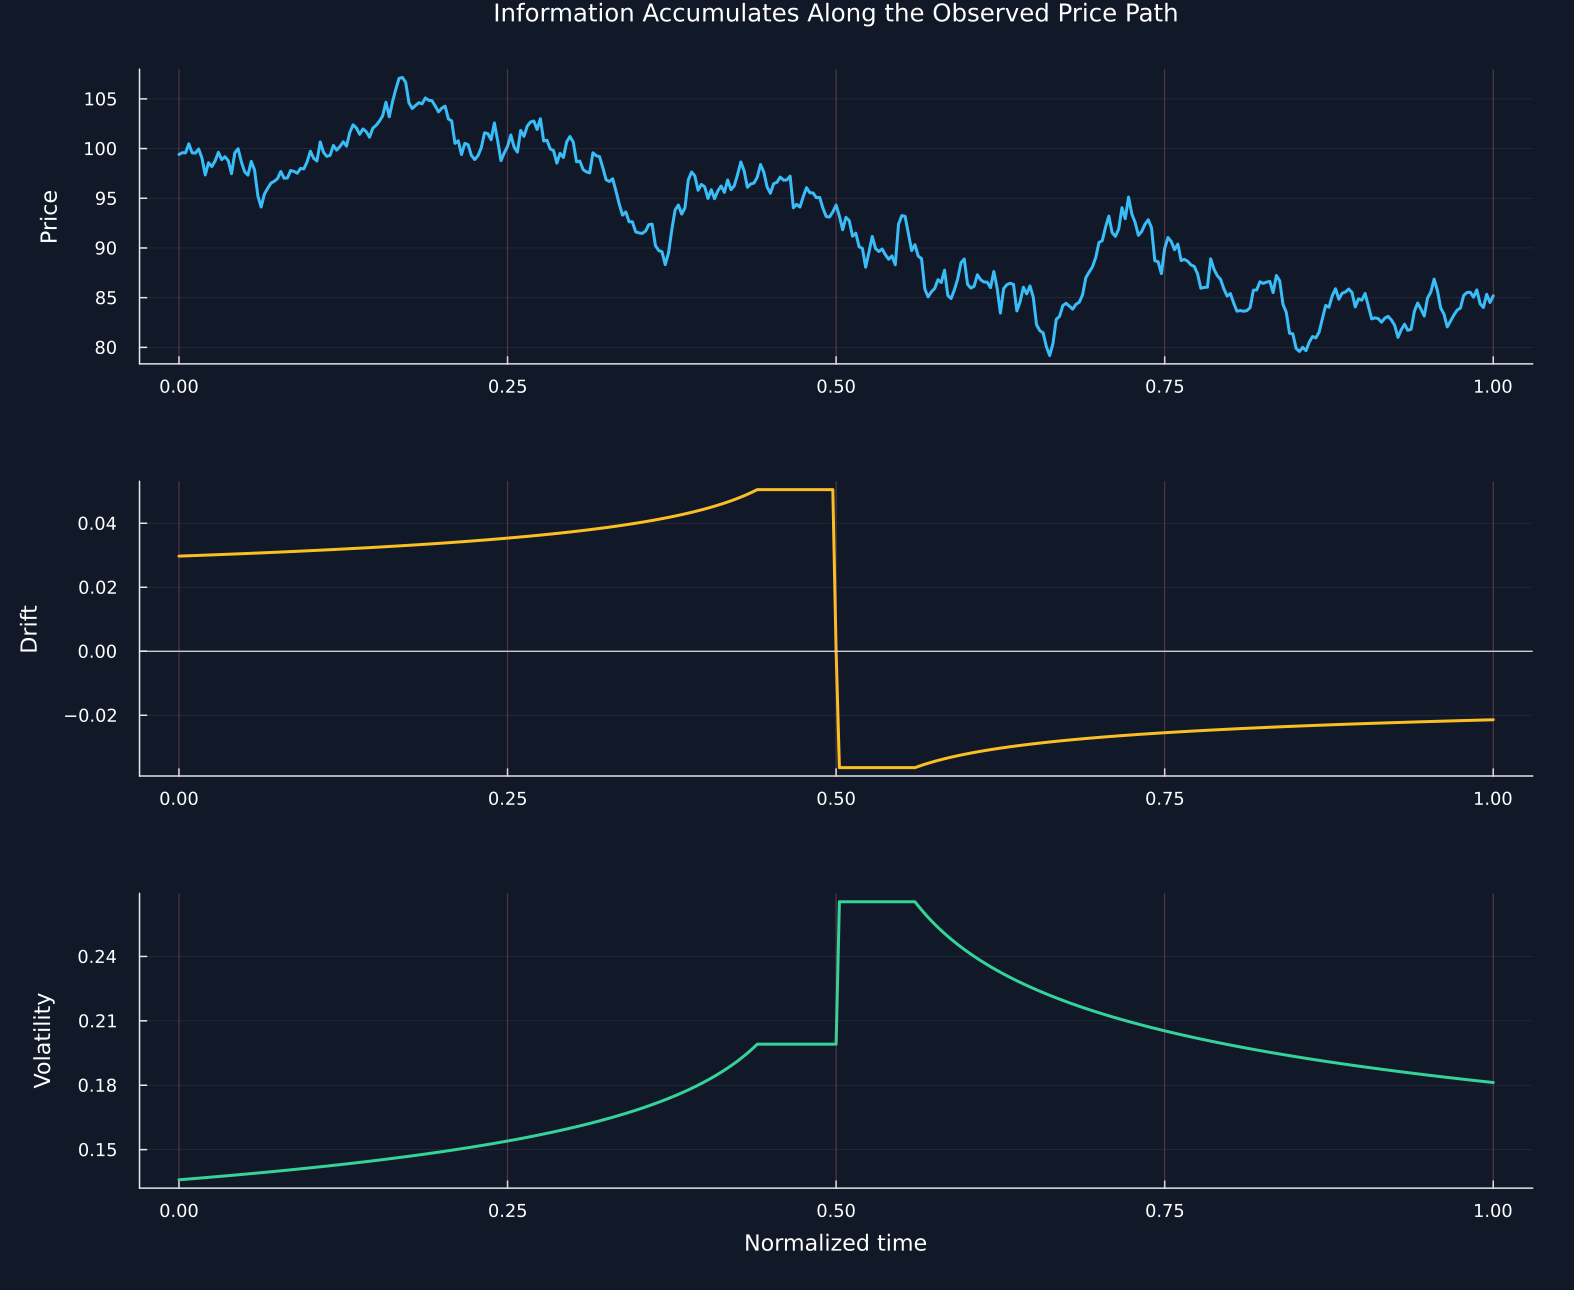

In [3]:
panels = [plot(time, price_path; color=palette.cyan, ylabel="Price", title="Information Accumulates Along the Observed Price Path", legend=false), plot(time, drift; color=palette.amber, ylabel="Drift", legend=false), plot(time, volatility; color=palette.green, ylabel="Volatility", xlabel="Normalized time", legend=false)]
hline!(panels[2], [0.]; color=palette.text, linewidth=.8)
for panel in panels
    vline!(panel, time[selected]; color=palette.rose, alpha=.22, linewidth=.8, label="")
end
figure = plot(panels...; layout=(3, 1), link=:x, size=(1050, 860))
save_figure(figure, paths, "information_filtration")


## Innovations

The innovation is the part of the return that could not be predicted from earlier information:

$$
U_t=R_t-\mathbb E[R_t\mid\mathcal F_{t-1}],
\qquad
\mathbb E[U_t\mid\mathcal F_{t-1}]=0.
$$

Here, $U_t$ is the innovation; $R_t$ is the observed return; $\mathcal F_{t-1}$ is information known one step earlier. $\mathbb E[R_t\mid\mathcal F_{t-1}]$ is the predicted return, and the second equality states that the remaining surprise has conditional mean zero.

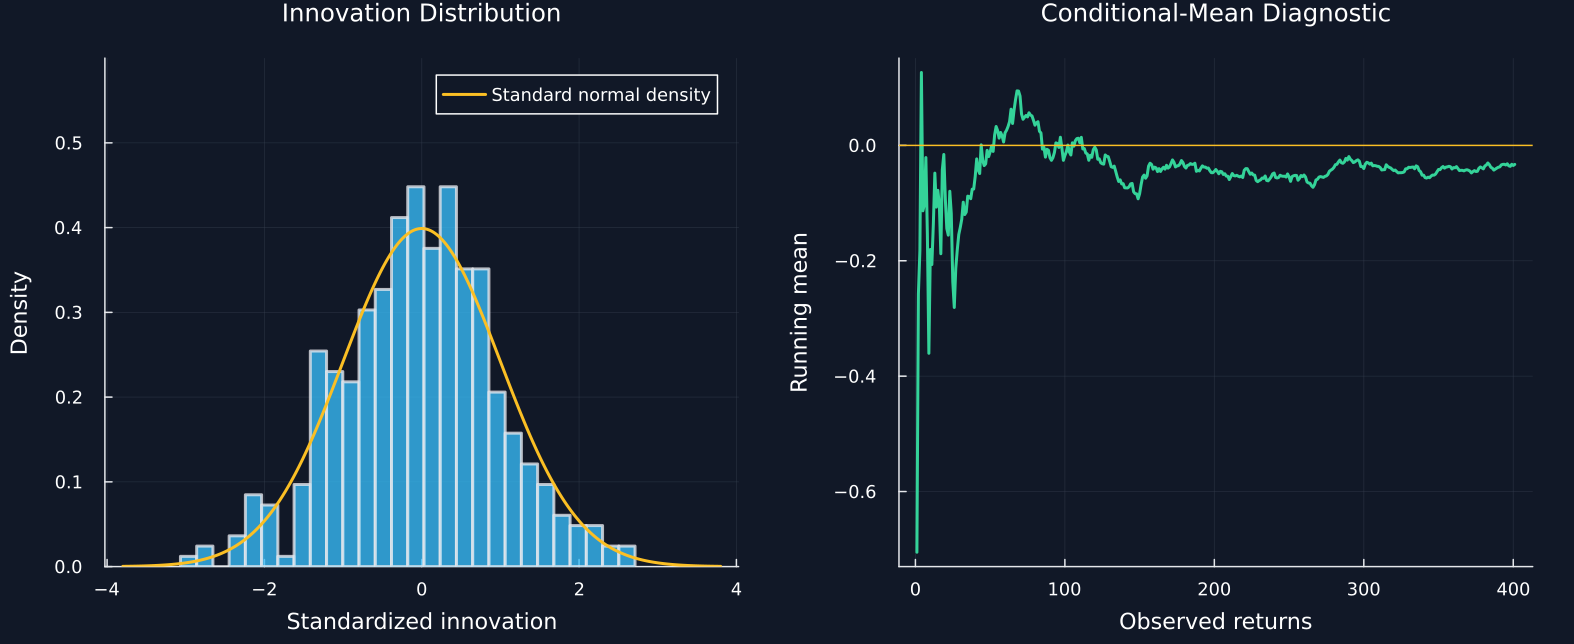

In [4]:
density_grid = collect(range(-3.8, 3.8; length=300))
normal_density = exp.(-0.5 .* density_grid.^2)./sqrt(2pi)
running_mean = cumsum(standardized_innovation)./information_count
innovation_series = DataFrame("Observed returns"=>information_count, "Standardized innovation"=>standardized_innovation, "Running mean"=>running_mean)
innovation_density = DataFrame("Standardized innovation"=>density_grid, "Standard normal density"=>normal_density)
save_data(innovation_series, paths, "innovation_series")
save_data(innovation_density, paths, "innovation_density")
edges = range(minimum(standardized_innovation), maximum(standardized_innovation); length=29)
distribution_panel = histogram(standardized_innovation; bins=edges, normalize=:pdf, color=palette.cyan, alpha=.78, xlabel="Standardized innovation", ylabel="Density", title="Innovation Distribution", ylims=(0, .6), label="")
plot!(distribution_panel, density_grid, normal_density; color=palette.amber, label="Standard normal density")
mean_panel = plot(information_count, running_mean; color=palette.green, xlabel="Observed returns", ylabel="Running mean", title="Conditional-Mean Diagnostic", legend=false)
hline!(mean_panel, [0.]; color=palette.amber, linewidth=1)
figure = plot(distribution_panel, mean_panel; layout=(1, 2), size=(1050, 430))
save_figure(figure, paths, "innovation_diagnostics")


## Tests

In [5]:
midpoint = observation_count÷2+1
repeated_innovation = randn(Xoshiro(20260925), observation_count)
@assert size(drift) == (observation_count,)
@assert size(volatility) == (observation_count,)
@assert drift[midpoint] == 0
@assert volatility[midpoint] == volatility[midpoint-1]
@assert all(volatility .> 0)
@assert all(isfinite, price_path)
@assert all(price_path .> 0)
@assert innovation == repeated_innovation
@assert abs(mean(standardized_innovation)) < .15
@assert nrow(information_table) == length(selected)
@assert standardized_innovation ≈ innovation atol=2e-14
